<a href="https://colab.research.google.com/github/YanuarRamadhaniKuswoko/Pembelajaran_Mesin_2026/blob/main/TG4_244107020172_Yanuar_Ramadhani_Kuswoko.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Praktikum 1

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Seleksi Fitur

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

display(df.head())

df = pd.read_csv('Iris.csv')


X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

display(X.head())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Plot Data
Karena data 4 dimensi, maka akan kita coba
plot cluster berdasarkan Sepal Length dan Sepal Width  saja

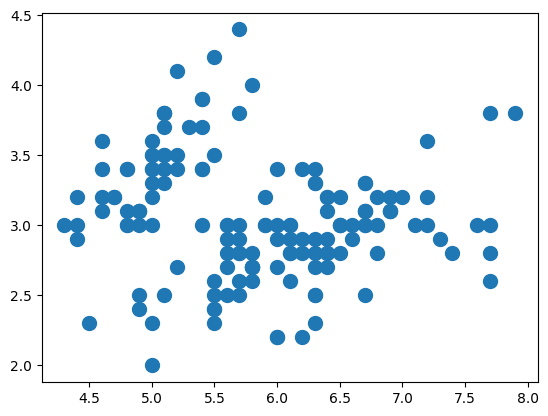

In [12]:
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

Buat Model KMeans
Kali ini kita coba menggunakan k=2 - anggap saja kita tidak tahu jumlah label ada 3 :)

In [13]:
from sklearn.cluster import KMeans

Inisiasi obyek KMeans

In [14]:
cl_kmeans = KMeans(n_clusters=2)

Fit dan predict model

In [15]:
y_kmeans = cl_kmeans.fit_predict(X)

Plot hasi cluster berdasarkan Sepal Length dan Sepal Width

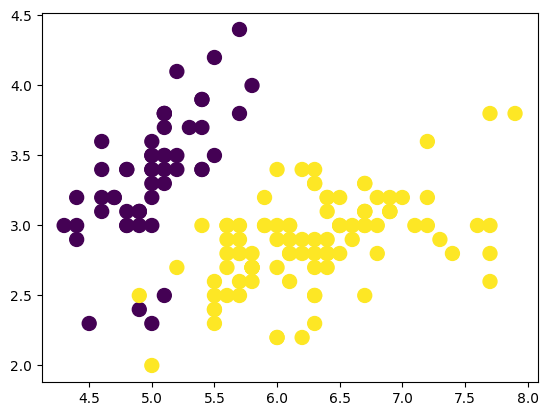

In [16]:
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

Plot centroid

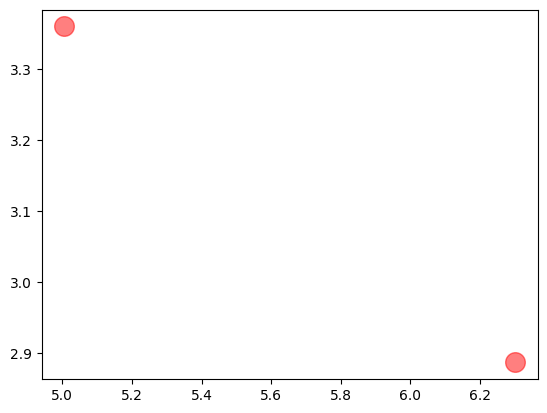

In [17]:
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

Nanti akan muncul tampilan seperti dibawah ini

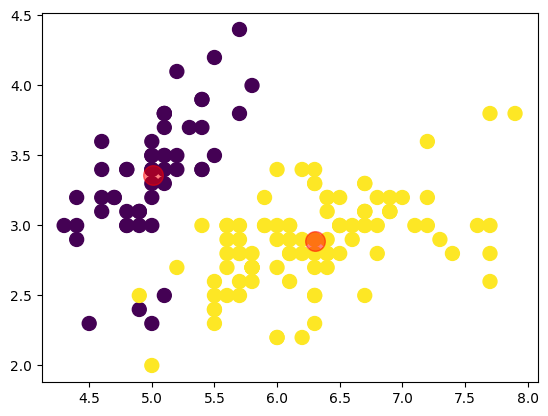

In [18]:
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

Cek Nilai SSE

In [19]:
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733915


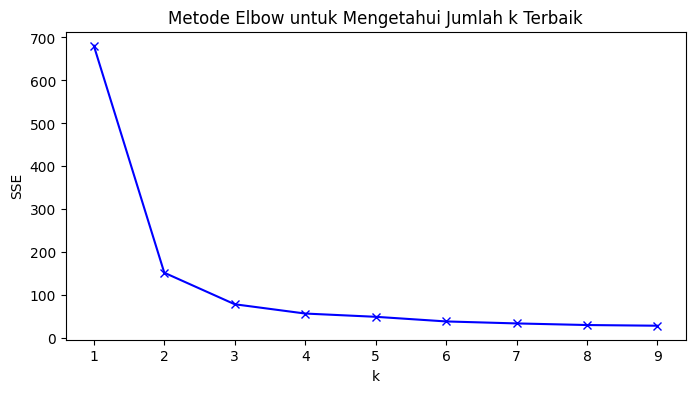

In [21]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
 kmeanModel = KMeans(n_clusters=k)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)


# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

Cek Nilai SSE setiap k

In [22]:
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=680.8243999999996
k=2; SSE=152.36870647733915
k=3; SSE=78.94506582597728
k=4; SSE=57.34540931571815
k=5; SSE=49.75817673992674
k=6; SSE=38.96478785103787
k=7; SSE=34.332858416945356
k=8; SSE=30.61185108114392
k=9; SSE=28.994770053475946


## Praktikum 2

import library

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

Pengantar k-Means

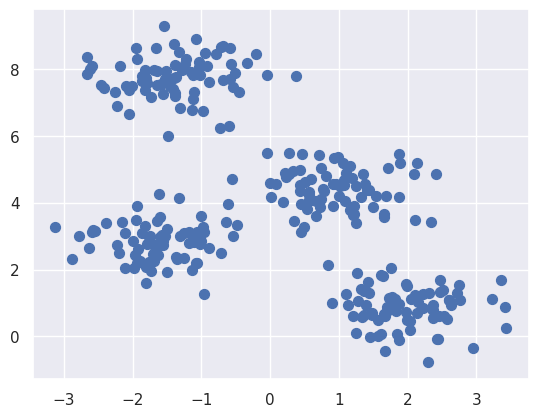

In [24]:
from sklearn.datasets import make_blobs
X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.60, random_state=0)
plt.scatter(X[:, 0], X[:, 1], s=50);

In [25]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

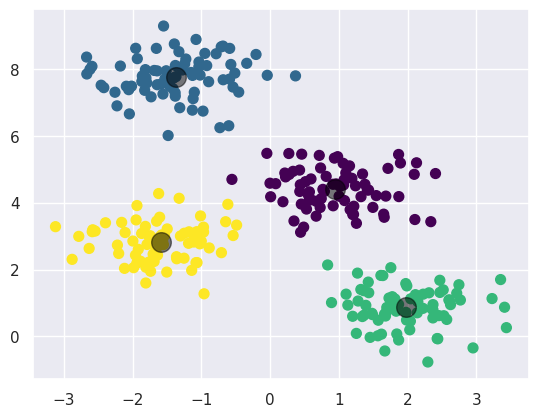

In [26]:
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)

Algoritma Expectation-Maximization

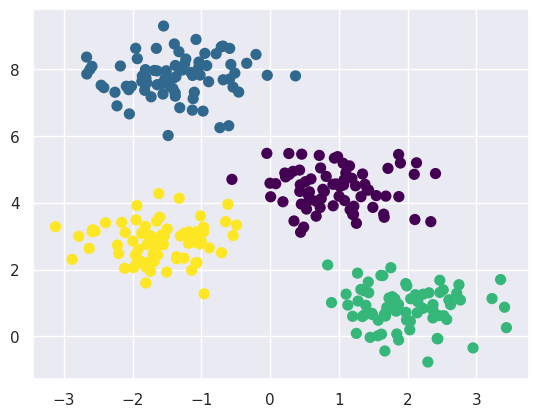

In [27]:
from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2):
    # 1. Randomly choose clusters
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]

    while True:
        # 2a. input label center yang baru
        labels = pairwise_distances_argmin(X, centers)

        # 2b. update center dari titik baru
        new_centers = np.array([X[labels == i].mean(0)
                                for i in range(n_clusters)])

        # 2c. cek konvergensi
        if np.all(centers == new_centers):
            break
        centers = new_centers

    return centers, labels

centers, labels = find_clusters(X, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

Perubahan random

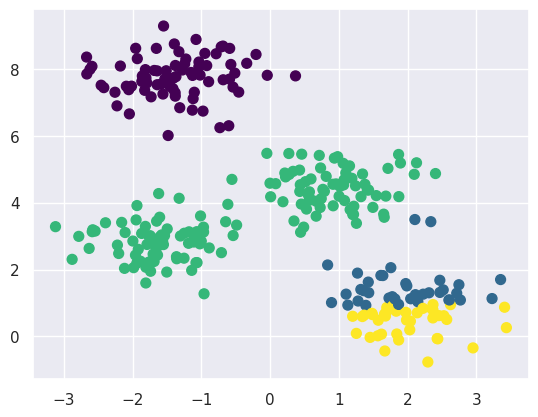

In [28]:
centers, labels = find_clusters(X, 4, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

Optimalisasi Jumlah Klaster

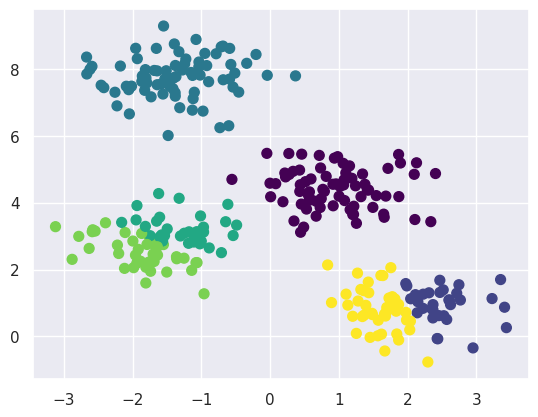

In [29]:
labels = KMeans(6, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

Batas Klaster yang Tidak Selalu Linier

In [30]:
from sklearn.datasets import make_moons
X, y = make_moons(200, noise=.05, random_state=0)

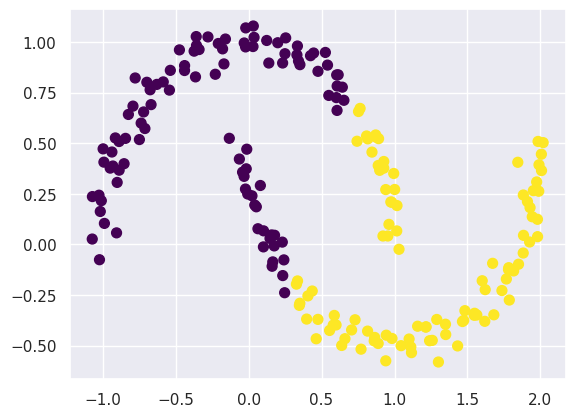

In [31]:
labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


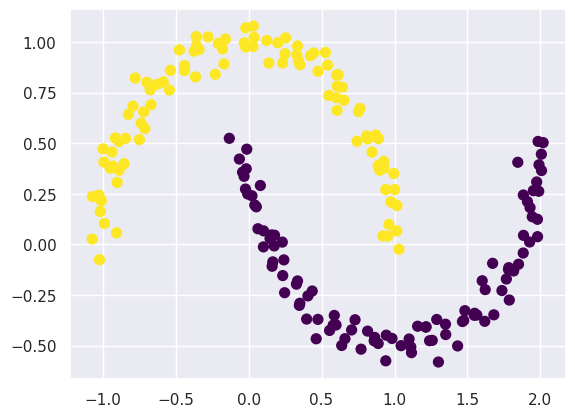

In [32]:
from sklearn.cluster import SpectralClustering
model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors',
                           assign_labels='kmeans')
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

## Contoh Kasus 1: Karakter Angka

In [33]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.data.shape

(1797, 64)

In [34]:
# terapkan K-Means
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits.data)
kmeans.cluster_centers_.shape

(10, 64)

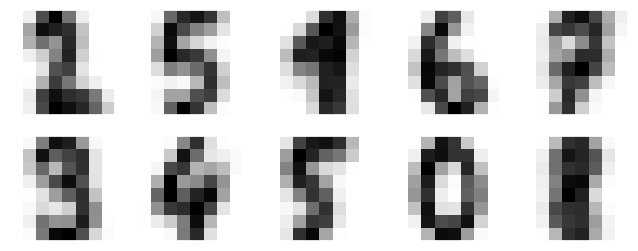

In [35]:
fig, ax = plt.subplots(2, 5, figsize=(8, 3))
centers = kmeans.cluster_centers_.reshape(10, 8, 8)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)

In [36]:
from scipy.stats import mode

labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

In [37]:
from sklearn.metrics import accuracy_score
accuracy_score(digits.target, labels)

0.7440178074568725

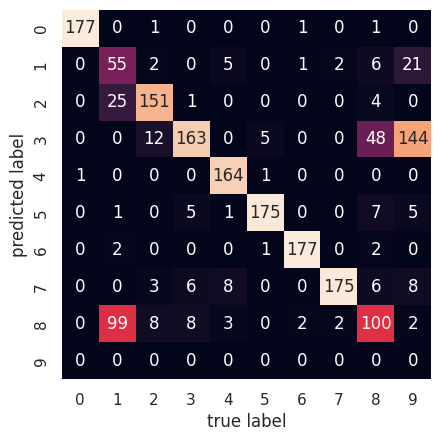

In [38]:
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(digits.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=digits.target_names,
            yticklabels=digits.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label');

In [39]:
from sklearn.manifold import TSNE


tsne = TSNE(n_components=2, init='random', random_state=0)
digits_proj = tsne.fit_transform(digits.data)

# hitung klaster
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits_proj)

# permutasi label
labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

# hitung akurasi
accuracy_score(digits.target, labels)

0.9410127991096272

## Studi Kasus 2: Kompresi Citra

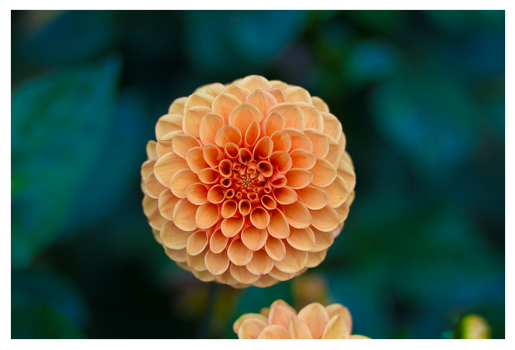

In [40]:
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower);

In [41]:
flower.shape

(427, 640, 3)

In [42]:
data = flower / 255.0
data = data.reshape(427 * 640, 3)
data.shape

(273280, 3)

In [43]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

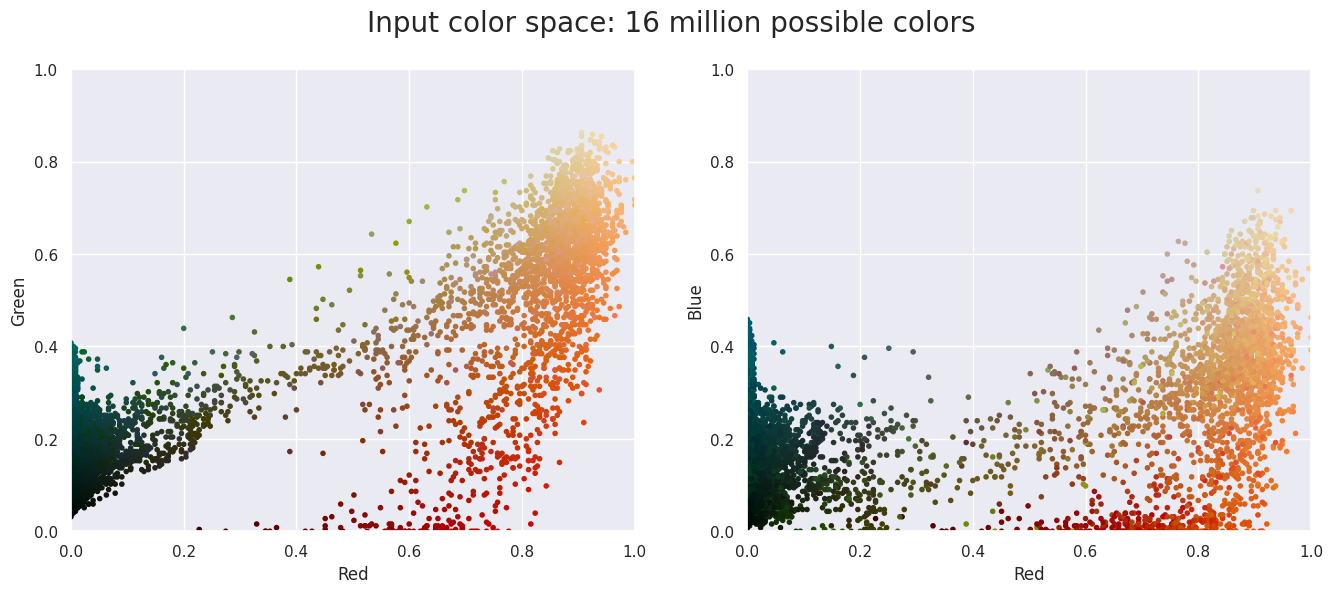

In [44]:
plot_pixels(data, title='Input color space: 16 million possible colors')

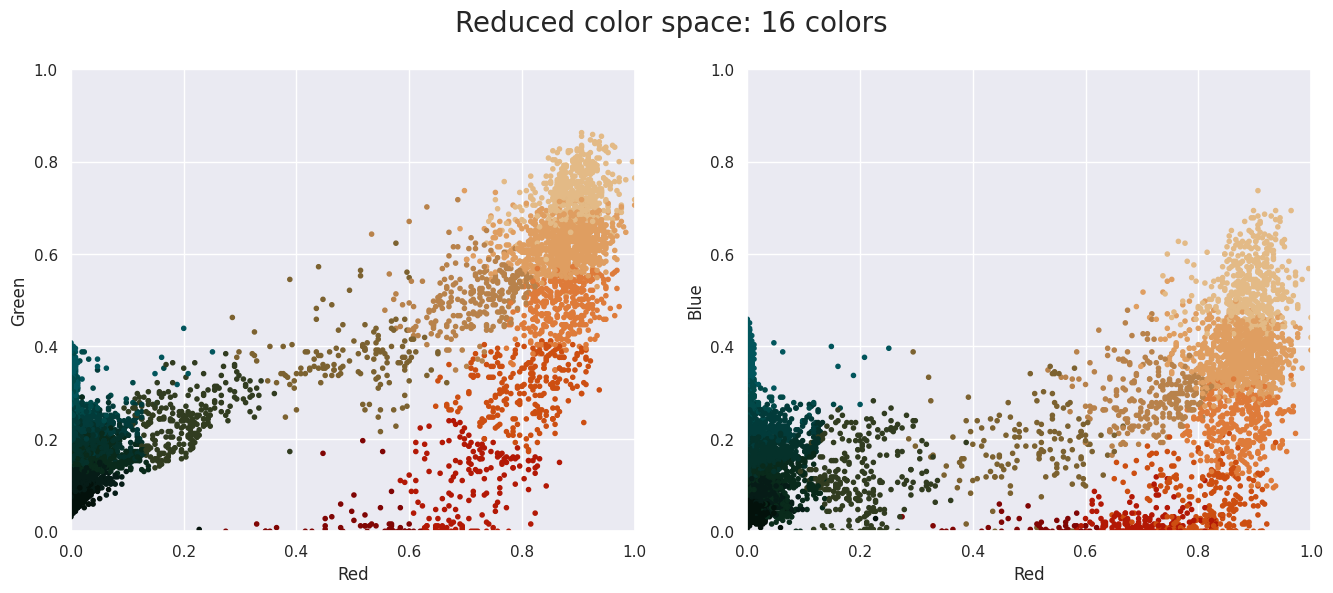

In [45]:
import warnings; warnings.simplefilter('ignore')  # Fix NumPy issues.

from sklearn.cluster import MiniBatchKMeans
kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors,title="Reduced color space: 16 colors")

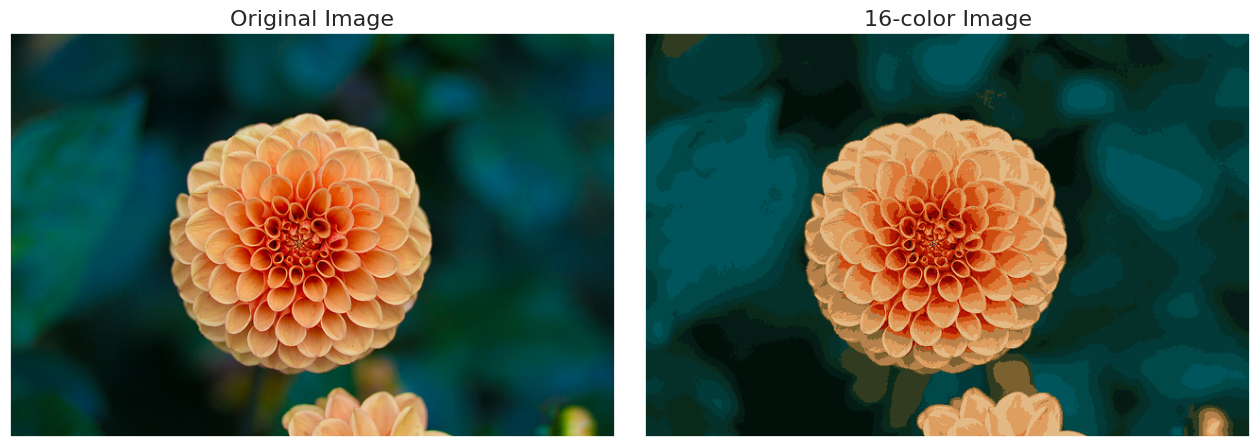

In [46]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

## Praktikum 3
Pembuatan Dataset Sintetis

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn import metrics

In [51]:
# Menentukan titik pusat cluster
centers = [[1, 1], [-1, -1], [1, -1]]

# Generate data
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=0.4, random_state=0
)

# Standarisasi fitur agar memiliki rerata 0 dan varians 1
X = StandardScaler().fit_transform(X)

Visualisasikan data yang dihasilkan dengan cara ini:

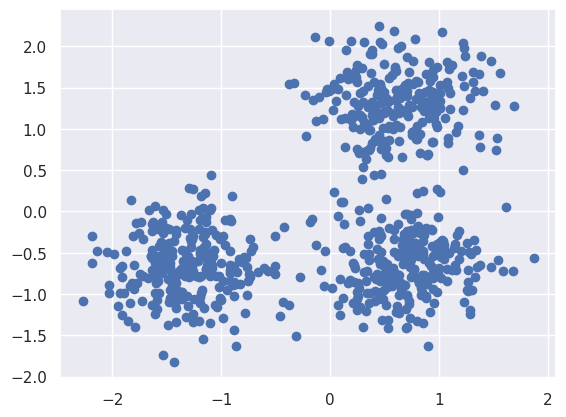

In [54]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])

plt.show()

Compute DBSCAN

In [56]:
import numpy as np

from sklearn import metrics
from sklearn.cluster import DBSCAN  # 1. Tambahkan DBSCAN di sini

# 2. Tambahkan DBSCAN sebelum tanda kurung (eps=...)
db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 3
Estimated number of noise points: 18


Evaluasi Kualitas Klasterisasi

In [58]:
from sklearn import metrics

# Memanggil fungsi metrik evaluasi dari modul sklearn.metrics
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(
    "Adjusted Mutual Information:"
    f" {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}"
)
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


Visualisasi Hasil Klasterisasi

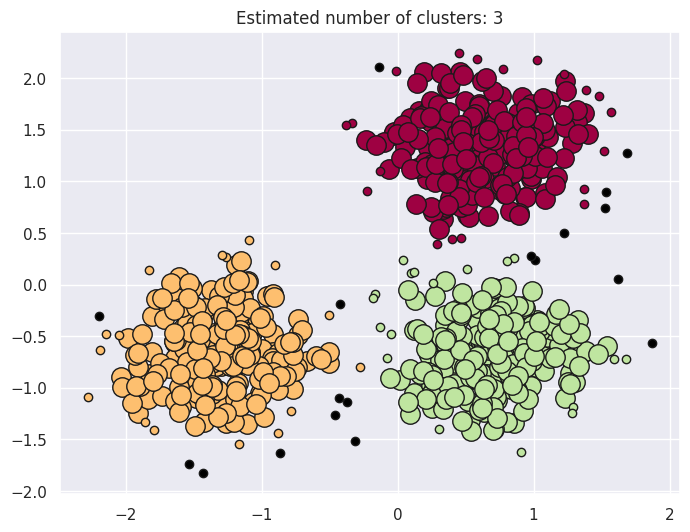

In [61]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Mendapatkan label unik
unique_labels = set(labels)

# 2. Membuat boolean mask untuk core samples
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

# 3. Membuat pemetaan warna untuk setiap cluster
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

plt.figure(figsize=(8, 6))

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Warna hitam [R, G, B, Alpha] khusus untuk titik noise/outlier
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    # Plot titik Core (ukuran besar: markersize=14)
    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    # Plot titik Non-Core / Border / Noise (ukuran kecil: markersize=6)
    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )

# 4. Menambahkan judul dan menampilkan grafik
plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.show()

Interpretasi visual:

*   Titik besar berwarna → core samples dalam klaster.
*   Titik kecil berwarna → non-core samples, tetap termasuk klaster.
*   Titik hitam → noise/outlier.

### TUGAS PRAKTIKUM

##1. Tugas K-Means

Buatlah sebuah model K-Means dengan ketentuan,

1.Gunakan data 'Mall_Customers.csv'

2.Tentukan fitur apa yang tepat untuk melakukan clustering (minimal 2)

jawab:
Fitur paling relevan dan standar yang digunakan adalah:

-Annual Income (k$) (Pendapatan Tahunan)

-Spending Score (1-100) (Skor Pengeluaran/Belanja)

Alasan:
Fitur ini memberikan gambaran langsung mengenai profil finansial dan perilaku belanja pelanggan. Fitur seperti CustomerID dibuang karena hanya identitas unik, dan Gender dibuang agar fokus pada fitur kuantitatif numerik.

3.Buatlah model K-Means dengan mempertimbangkan jumlah k k yang terbaik.

--- 5 Baris Pertama Data ---


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


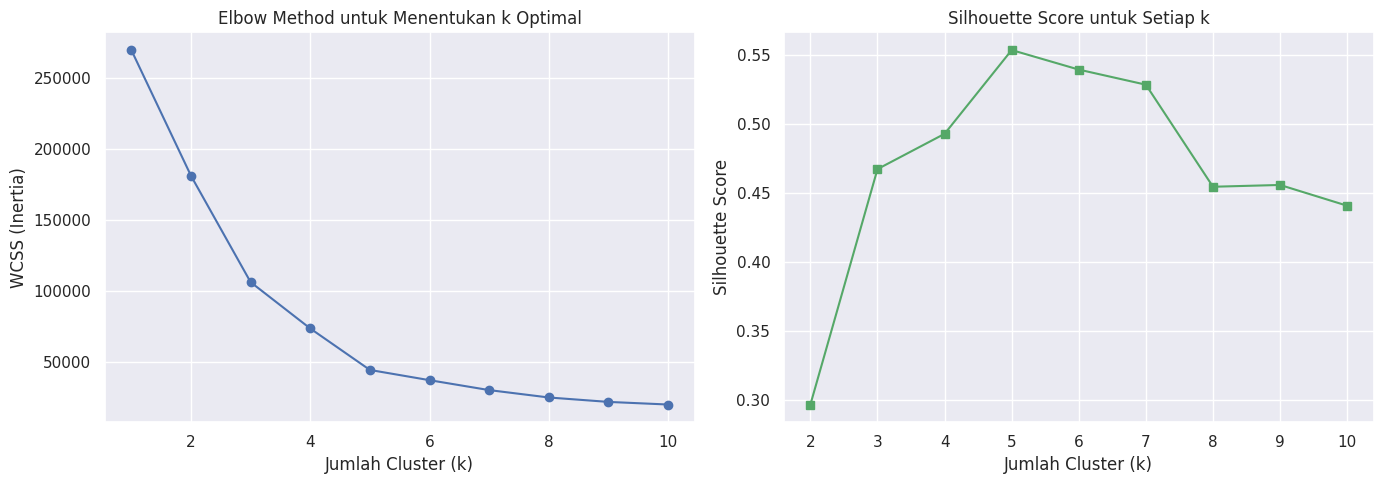

k = 2 | Silhouette Score = 0.2969
k = 3 | Silhouette Score = 0.4676
k = 4 | Silhouette Score = 0.4932
k = 5 | Silhouette Score = 0.5539
k = 6 | Silhouette Score = 0.5398
k = 7 | Silhouette Score = 0.5288
k = 8 | Silhouette Score = 0.4548
k = 9 | Silhouette Score = 0.4561
k = 10 | Silhouette Score = 0.4411


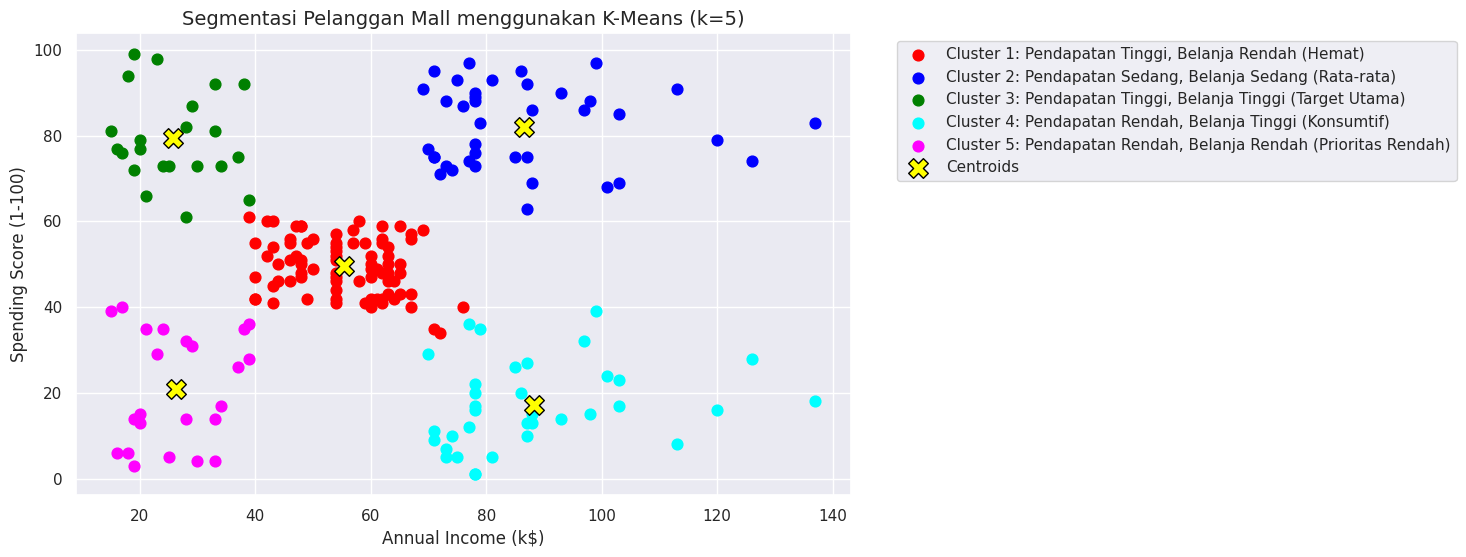

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ==========================================
# 1. LOAD DATASET & SELEKSI FITUR
# ==========================================
# Load dataset Mall_Customers.csv
df = pd.read_csv('Mall_Customers.csv')

# Menampilkan 5 data pertama
print("--- 5 Baris Pertama Data ---")
display(df.head())

# Seleksi Fitur: Annual Income dan Spending Score (Kolom indeks 3 dan 4)
X = df.iloc[:, [3, 4]].values


# ==========================================
# 2. MENENTUKAN k TERBAIK (ELBOW METHOD & SILHOUETTE SCORE)
# ==========================================
wcss = []
silhouette_scores = []
K_range = range(2, 11)

# Hitung WCSS untuk Elbow Method (termasuk k=1)
wcss_all = []
for k in range(1, 11):
    kmeans_test = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans_test.fit(X)
    wcss_all.append(kmeans_test.inertia_)

# Hitung Silhouette Score untuk k=2 hingga 10
for k in K_range:
    kmeans_test = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    cluster_labels = kmeans_test.fit_predict(X)
    score = silhouette_score(X, cluster_labels)
    silhouette_scores.append(score)

# Visualisasi Elbow Method & Silhouette Score
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Elbow Method
ax1.plot(range(1, 11), wcss_all, marker='o', color='b')
ax1.set_title('Elbow Method untuk Menentukan k Optimal')
ax1.set_xlabel('Jumlah Cluster (k)')
ax1.set_ylabel('WCSS (Inertia)')
ax1.grid(True)

# Plot Silhouette Score
ax2.plot(K_range, silhouette_scores, marker='s', color='g')
ax2.set_title('Silhouette Score untuk Setiap k')
ax2.set_xlabel('Jumlah Cluster (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True)

plt.tight_layout()
plt.show()

# Menampilkan nilai Silhouette Score
for k, score in zip(K_range, silhouette_scores):
    print(f"k = {k} | Silhouette Score = {score:.4f}")


# ==========================================
# 3. PEMBUATAN MODEL K-MEANS TERBAIK (k=5) & VISUALISASI
# ==========================================
# Berdasarkan evaluasi, k=5 adalah jumlah cluster terbaik
k_optimum = 5
kmeans = KMeans(n_clusters=k_optimum, init='k-means++', random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X)

# Visualisasi Hasil Cluster K-Means
plt.figure(figsize=(10, 6))

colors = ['red', 'blue', 'green', 'cyan', 'magenta']
labels_cluster = [
    'Cluster 1: Pendapatan Tinggi, Belanja Rendah (Hemat)',
    'Cluster 2: Pendapatan Sedang, Belanja Sedang (Rata-rata)',
    'Cluster 3: Pendapatan Tinggi, Belanja Tinggi (Target Utama)',
    'Cluster 4: Pendapatan Rendah, Belanja Tinggi (Konsumtif)',
    'Cluster 5: Pendapatan Rendah, Belanja Rendah (Prioritas Rendah)'
]

for i in range(k_optimum):
    plt.scatter(
        X[y_kmeans == i, 0],
        X[y_kmeans == i, 1],
        s=60,
        c=colors[i],
        label=labels_cluster[i]
    )

# Plot Centroid (Titik Pusat Cluster)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    c='yellow',
    marker='X',
    edgecolor='black',
    label='Centroids'
)

plt.title('Segmentasi Pelanggan Mall menggunakan K-Means (k=5)', fontsize=14)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

## 2. Tugas DBSCAN
1.Buat dataset make_moons (1000 sampel, noise=0.05), lalu normalisasi.

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn import metrics

# 1. Generate dataset make_moons (1000 sampel, noise=0.05)
X, y_true = make_moons(n_samples=1000, noise=0.05, random_state=42)

# 2. Normalisasi data menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Status Nomor 1: Dataset berhasil dibuat dan dinormalisasi.")
print("Bentuk dataset (X_scaled):", X_scaled.shape)

Status Nomor 1: Dataset berhasil dibuat dan dinormalisasi.
Bentuk dataset (X_scaled): (1000, 2)


2.Jalankan DBSCAN dengan eps=0.2,min_samples=5, hitung jumlah klaster & noise.

In [64]:
# Inisialisasi dan fitting model DBSCAN
db = DBSCAN(eps=0.2, min_samples=5).fit(X_scaled)
labels = db.labels_

# Menghitung jumlah klaster (mengabaikan noise yang berlabel -1)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)

# Menghitung jumlah titik noise (label -1)
n_noise_ = list(labels).count(-1)

print("=== HASIL DBSCAN (Soal 2) ===")
print(f"Jumlah Klaster Terbentuk : {n_clusters_}")
print(f"Jumlah Titik Noise      : {n_noise_}")

=== HASIL DBSCAN (Soal 2) ===
Jumlah Klaster Terbentuk : 2
Jumlah Titik Noise      : 0


3.Evaluasi dengan metrik: Homogeneity, Completeness, V-measure, ARI, AMI, Silhouette.

In [65]:
# Hitung metrik evaluasi klasterisasi
homogeneity = metrics.homogeneity_score(y_true, labels)
completeness = metrics.completeness_score(y_true, labels)
v_measure = metrics.v_measure_score(y_true, labels)
ari = metrics.adjusted_rand_score(y_true, labels)
ami = metrics.adjusted_mutual_info_score(y_true, labels)
silhouette = metrics.silhouette_score(X_scaled, labels)

print("=== HASIL EVALUASI METRIK (Soal 3) ===")
print(f"Homogeneity Score       : {homogeneity:.3f}")
print(f"Completeness Score      : {completeness:.3f}")
print(f"V-measure Score         : {v_measure:.3f}")
print(f"Adjusted Rand Index (ARI): {ari:.3f}")
print(f"Adjusted Mutual Info(AMI): {ami:.3f}")
print(f"Silhouette Coefficient  : {silhouette:.3f}")

=== HASIL EVALUASI METRIK (Soal 3) ===
Homogeneity Score       : 1.000
Completeness Score      : 1.000
V-measure Score         : 1.000
Adjusted Rand Index (ARI): 1.000
Adjusted Mutual Info(AMI): 1.000
Silhouette Coefficient  : 0.391


4.Visualisasikan hasil DBSCAN (core sample = titik besar, non-core = titik kecil, noise = hitam).

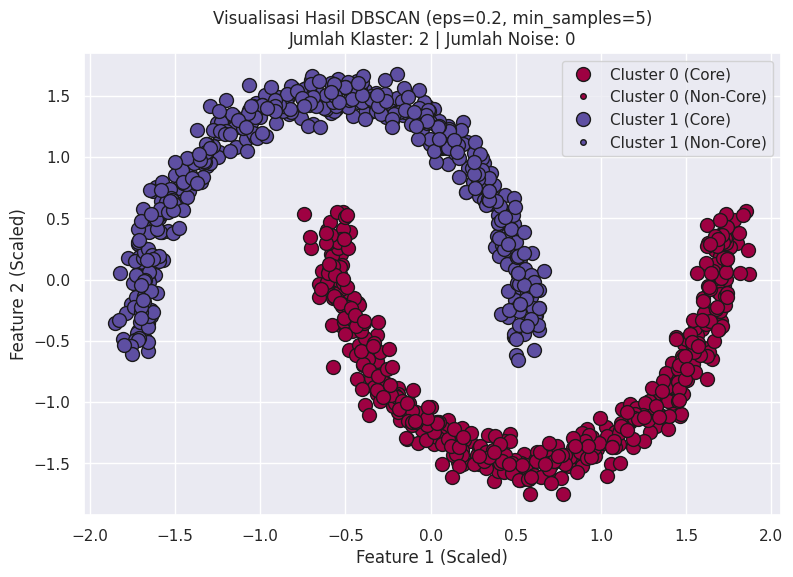

In [66]:
# 1. Membuat boolean mask untuk core samples
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

# 2. Menentukan pemetaan warna untuk setiap cluster
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

plt.figure(figsize=(9, 6))

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Warna hitam khusus untuk noise
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    # Core Samples (titik besar: markersize=10)
    xy = X_scaled[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=10,
        label=f'Cluster {k} (Core)' if k != -1 else 'Noise'
    )

    # Non-Core / Border Samples (titik kecil: markersize=4)
    xy = X_scaled[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=4,
        label=f'Cluster {k} (Non-Core)' if k != -1 else ''
    )

plt.title(f'Visualisasi Hasil DBSCAN (eps=0.2, min_samples=5)\nJumlah Klaster: {n_clusters_} | Jumlah Noise: {n_noise_}')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

5.Lakukan eksperimen:
*   eps = 0.05, 0.1, 0.3, 0.5
*   min_samples = 3, 10, 20
*   Catat perubahan klaster, noise, dan kualitas evaluasi.

In [67]:
# Daftar nilai parameter yang dieksperimenkan
eps_values = [0.05, 0.1, 0.3, 0.5]
min_samples_values = [3, 10, 20]

results = []

for eps in eps_values:
    for ms in min_samples_values:
        # Inisialisasi & fitting model DBSCAN untuk setiap kombinasi
        model = DBSCAN(eps=eps, min_samples=ms).fit(X_scaled)
        lbls = model.labels_

        # Hitung jumlah klaster dan noise
        n_c = len(set(lbls)) - (1 if -1 in lbls else 0)
        n_n = list(lbls).count(-1)

        # Hitung metrik evaluasi
        v_m = metrics.v_measure_score(y_true, lbls)
        ari = metrics.adjusted_rand_score(y_true, lbls)

        # Silhouette score hanya bisa dihitung jika jumlah klaster > 1
        if n_c > 1:
            sil = metrics.silhouette_score(X_scaled, lbls)
            sil_str = f"{sil:.3f}"
        else:
            sil_str = "N/A"

        results.append({
            'eps': eps,
            'min_samples': ms,
            'Jumlah Klaster': n_c,
            'Jumlah Noise': n_n,
            'ARI': f"{ari:.3f}",
            'V-Measure': f"{v_m:.3f}",
            'Silhouette': sil_str
        })

# Tampilkan ringkasan hasil eksperimen dalam bentuk tabel Pandas DataFrame
df_results = pd.DataFrame(results)
print("=== TABEL CATATAN HASIL EKSPERIMEN PARAMETER DBSCAN ===")
display(df_results)

=== TABEL CATATAN HASIL EKSPERIMEN PARAMETER DBSCAN ===


,eps,min_samples,Jumlah Klaster,Jumlah Noise,ARI,V-Measure,Silhouette
0,0.05,3,69,186,0.030,0.257,0.113
1,0.05,10,3,970,0.002,0.049,-0.294
2,0.05,20,0,1000,0.000,0.000,N/A
3,0.10,3,2,14,0.972,0.943,0.252
4,0.10,10,7,57,0.523,0.571,0.162
5,0.10,20,6,850,0.017,0.155,-0.360
6,0.30,3,2,0,1.000,1.000,0.391
7,0.30,10,2,0,1.000,1.000,0.391
8,0.30,20,2,0,1.000,1.000,0.391
9,0.50,3,2,0,1.000,1.000,0.391
